# 04 — Baseline & model benchmark

**Objective.** Compare nine classifiers under one leakage-free preprocessing contract using
5-fold stratified cross-validation. **Primary metric:** multiclass log loss. Out-of-fold
probabilities, fit times and learning curves are saved for evidence-based selection.

In [1]:
import sys, warnings, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
ROOT = Path.cwd()
for p in (ROOT, ROOT / "src"):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))

from src.cirrhosis import config, paths, data, features, preprocessing, models, evaluation, inference

paths.ensure_dirs()
for sub in ("data_quality", "cleaning", "experiments", "final_evaluation"):
    (paths.REPORTS_DIR / sub).mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", palette="Blues_d")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 12, "figure.autolayout": True})
SEED = config.RANDOM_SEED
print("Environment ready; seed =", SEED)

Environment ready; seed = 42


In [2]:
from sklearn.model_selection import learning_curve

train_df = pd.read_csv(paths.PROCESSED_DIR / "train.csv")
X = data.feature_matrix(train_df)
code = {label: i for i, label in enumerate(config.CLASS_LABELS)}
y = train_df[config.TARGET].map(code).astype(int)
candidates = models.get_candidates(SEED)
print("Candidates:", list(candidates))
print("Encoded target:", code)

Candidates: ['DummyPrior', 'LogisticRegression', 'DecisionTree', 'RandomForest', 'ExtraTrees', 'HistGradientBoosting', 'XGBoost', 'LightGBM', 'CatBoost']
Encoded target: {'C': 0, 'CL': 1, 'D': 2}


In [3]:
leaderboard, oof = evaluation.benchmark(X, y, candidates, include_n_days=True, seed=SEED)
display(leaderboard)
leaderboard.to_csv(paths.LEADERBOARD_PATH, index=False)
oof_columns = {}
for name, proba in oof.items():
    for i, label in enumerate(config.CLASS_LABELS):
        oof_columns[f"{name}_{label}"] = proba[:, i]
pd.DataFrame(oof_columns, index=y.index).to_csv(paths.OOF_PATH, index=False)

,model,include_n_days,log_loss,accuracy,f1_macro,fit_seconds
0,XGBoost,True,0.382883,0.853821,0.609660,8.88
1,LightGBM,True,0.388635,0.854821,0.624219,9.54
2,CatBoost,True,0.397089,0.849237,0.586971,8.52
3,RandomForest,True,0.410822,0.846404,0.554803,6.85
4,HistGradientBoosting,True,0.440640,0.848987,0.607064,16.66
5,LogisticRegression,True,0.444272,0.833069,0.555376,10.87
6,ExtraTrees,True,0.463343,0.827736,0.533413,4.30
7,DecisionTree,True,0.475508,0.834153,0.551479,0.67
8,DummyPrior,True,0.723581,0.670223,0.267518,0.51


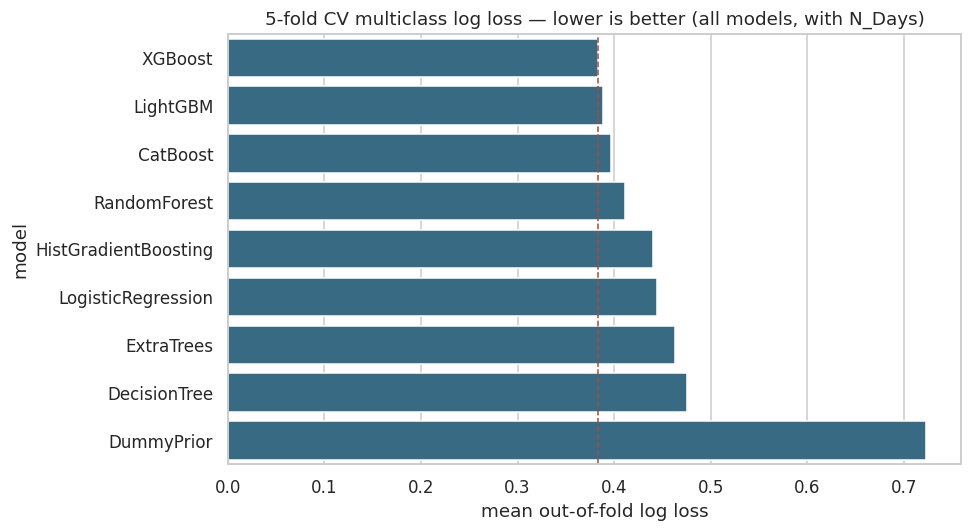

In [4]:
fig, ax = plt.subplots(figsize=(9, 5))
plot_df = leaderboard.sort_values("log_loss")
sns.barplot(data=plot_df, x="log_loss", y="model", ax=ax, color="#2B6E8F")
ax.axvline(plot_df["log_loss"].iloc[0], color="#A44A3F", ls="--", lw=1)
ax.set_title("5-fold CV multiclass log loss — lower is better (all models, with N_Days)")
ax.set_xlabel("mean out-of-fold log loss")
fig.savefig(paths.FIGURES_DIR / "04_cv_logloss.png", bbox_inches="tight")
plt.show()

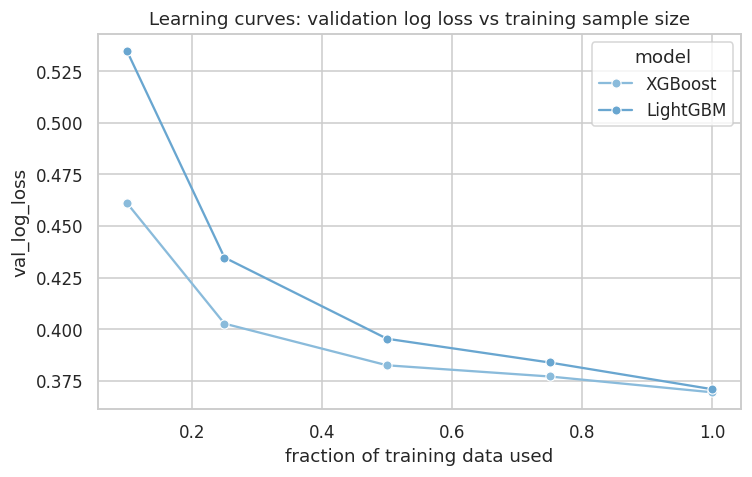

In [5]:
# Learning curves (10% -> 100%) for the two strongest non-dummy candidates.
top = [m for m in leaderboard["model"] if m != "DummyPrior"][:2]
val_df = pd.read_csv(paths.PROCESSED_DIR / "val.csv")
Xv = data.feature_matrix(val_df); yv = val_df[config.TARGET].map(code).astype(int)
fractions = [0.1, 0.25, 0.5, 0.75, 1.0]
rows = []
from sklearn.base import clone
for name in top:
    prototype = evaluation.make_pipeline(candidates[name], include_n_days=True)
    for frac in fractions:
        sub = X.sample(frac=frac, random_state=SEED)
        pipe = clone(prototype)
        pipe.fit(sub, y.loc[sub.index])
        p = pipe.predict_proba(Xv)
        rows.append({"model": name, "train_fraction": frac,
                     "val_log_loss": evaluation.score_predictions(yv, p)["log_loss"]})
curves = pd.DataFrame(rows)
curves.to_csv(paths.REPORTS_DIR / "experiments" / "learning_curves.csv", index=False)
fig, ax = plt.subplots(figsize=(7, 4.5))
sns.lineplot(data=curves, x="train_fraction", y="val_log_loss", hue="model", marker="o", ax=ax)
ax.set_title("Learning curves: validation log loss vs training sample size")
ax.set_xlabel("fraction of training data used")
fig.savefig(paths.FIGURES_DIR / "04_learning_curves.png", bbox_inches="tight")
plt.show()

## Interpretation & next steps

- All models are compared on identical folds; accuracy is reported but never used to select.
- The dummy prior gives the reference log loss that any useful model must beat.
- Learning curves show whether more data helps or whether the remaining error is irreducible.
- Next: ablate `N_Days`, tune the top candidates, calibrate probabilities and select the final
  model on the untouched validation split (notebook 05).